# Temporal Trends

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

df = df.drop_duplicates('order_id', ignore_index=True)

In [2]:
sns.set_theme()

from scripts import visualization_config

## How does order volume change over time?

In [3]:
orders_by_month = pd.DataFrame(df.groupby(df['order_date'].dt.to_period('M')).size())
orders_by_month['month'] = orders_by_month[0]
orders_by_month = orders_by_month.drop(columns=[0])

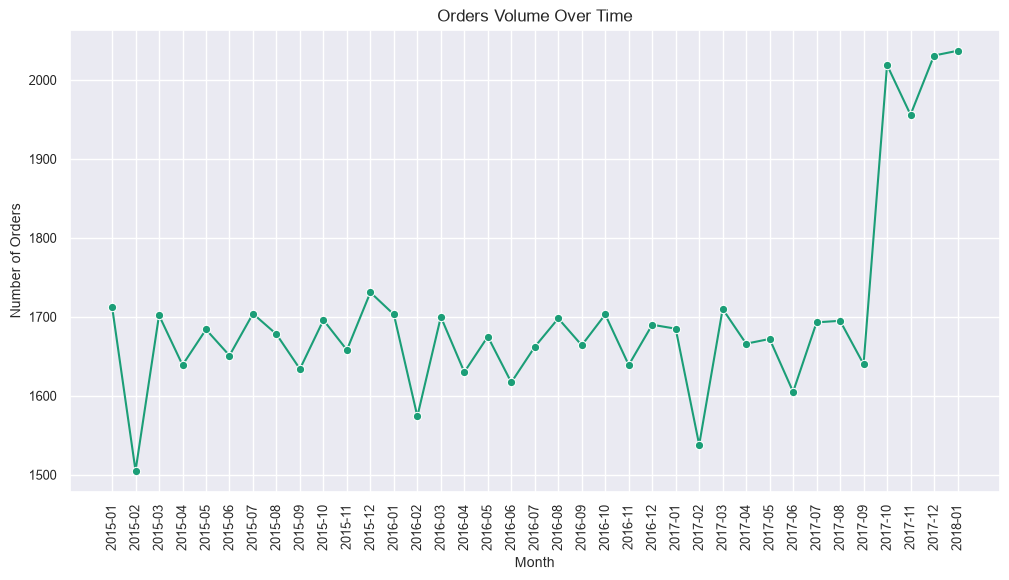

In [4]:
orders_by_month.index = orders_by_month.index.astype(str)

plt.figure(figsize=(12, 6))

sns.lineplot(data=orders_by_month, markers=True, legend=False, palette='Dark2')

plt.title('Orders Volume Over Time')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=90)

plt.savefig('../visualizations/orders-volume-over-time.png', bbox_inches='tight')
plt.show()

The chart clearly shows that order volumes were somewhere consistent up until September 2017. Then, there's a sudden spike in the last four months.

In [5]:
before_spike = orders_by_month.loc['2015-01':'2017-09']
after_spike = orders_by_month.loc['2017-10':'2018-01']

print(before_spike.describe())
print(after_spike.describe())

print(f'Average order volume difference in first 33 months and last 4 months: {int(after_spike.mean().iloc[0] - before_spike.mean().iloc[0])} orders')

             month
count    33.000000
mean   1662.242424
std      50.376104
min    1505.000000
25%    1639.000000
50%    1675.000000
75%    1698.000000
max    1731.000000
             month
count     4.000000
mean   2010.750000
std      37.259227
min    1956.000000
25%    2003.250000
50%    2025.000000
75%    2032.500000
max    2037.000000
Average order volume difference in first 33 months and last 4 months: 348 orders


From the two tables we can see that the average order volumes jumped by 348 in the last four months. The minimum number of orders also jumped from 1505 to 1956, and the maximum from 1731 to 2037.

With this data we can safely confirm that the last 4 months were the most successful, in terms of order volumes.

**NOTE**: This only counts order volumes. It doesn't count items per order, or profit.

## Are there seasonal or day-of-week patterns in delivery delays?

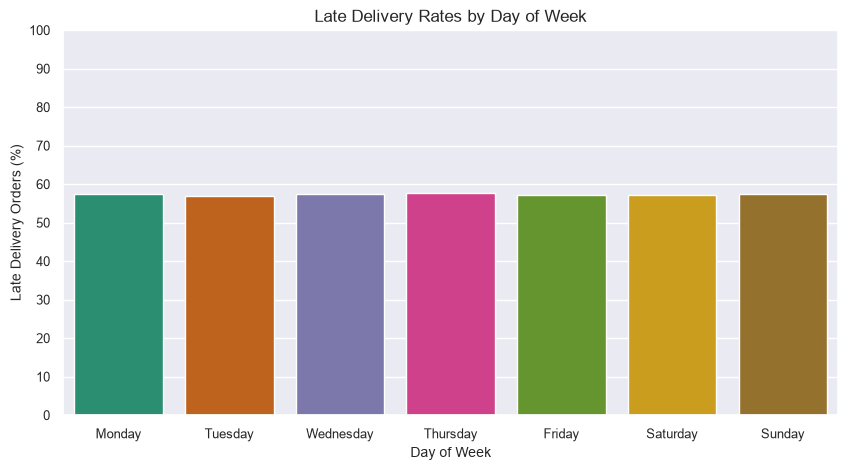

In [6]:
late_orders_df = df[df['late_delivery_risk'] == 1].reset_index()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

days_of_week_late_orders = (
    late_orders_df
    .groupby(late_orders_df['order_date'].dt.day_name())
    .size()
    .reindex(day_order, fill_value=0)
)

days_of_week_orders = (
    df
    .groupby(df['order_date'].dt.day_name())
    .size()
    .reindex(day_order, fill_value=0)
)

days_of_week_late_orders_rates = days_of_week_late_orders / days_of_week_orders * 100

plt.figure(figsize=(10, 5))

sns.barplot(
    x=days_of_week_late_orders_rates.index,
    y=days_of_week_late_orders_rates.values,
    hue=days_of_week_late_orders_rates.index,
    legend=False,
    palette='Dark2'
)

plt.yticks(ticks=np.arange(0, 101, 10))

plt.title('Late Delivery Rates by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Late Delivery Orders (%)')

plt.savefig('../visualizations/late-delivery-rates-by-day-of-week.png', bbox_inches='tight')
plt.show()

The chart shows that all days experience almost the same late delivery rates - ~57% - which is the same result we got when we compared late delivery rates between markets.

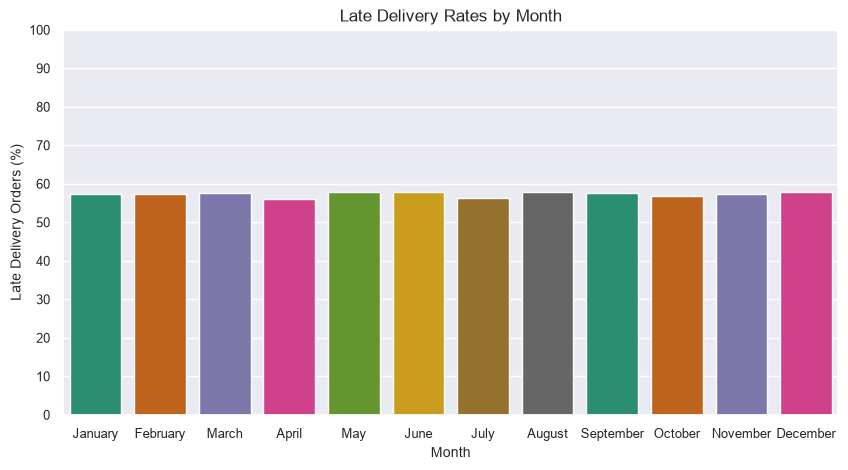

In [7]:
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

months_late_orders = (
    late_orders_df
    .groupby(late_orders_df['order_date'].dt.month)
    .size()
)

months_orders = (
    df
    .groupby(df['order_date'].dt.month)
    .size()
)

months_late_orders_rates = months_late_orders / months_orders * 100

plt.figure(figsize=(10, 5))

sns.barplot(
    x=months,
    y=months_late_orders_rates.values,
    hue=months,
    legend=False,
    palette='Dark2'
)

plt.yticks(ticks=np.arange(0, 101, 10))

plt.title('Late Delivery Rates by Month')
plt.xlabel('Month')
plt.ylabel('Late Delivery Orders (%)')

plt.savefig('../visualizations/late-delivery-rates-by-month.png', bbox_inches='tight')
plt.show()

The chart shows that all months experience almost the same delivery delay rates - ~57% - which is the same result we got for late delivery rates by day, and by market.

### Conclusion

There seems to be no patterns in seasonal and day-of-week delivery delays.

## Has shipping performance improved or deteriorated throughout the dataset period?

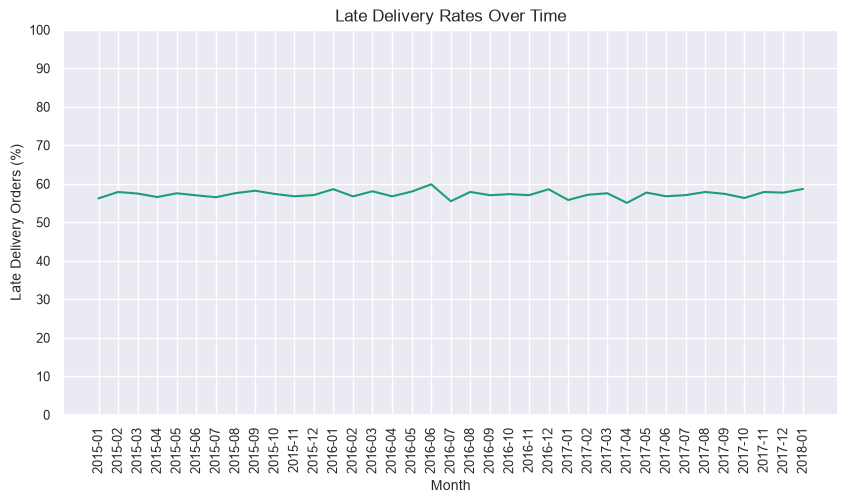

In [8]:
late_orders_over_time = (
    late_orders_df
    .groupby(late_orders_df['order_date'].dt.to_period('M'))
    .size()
)

orders_over_time = (
    df
    .groupby(df['order_date'].dt.to_period('M'))
    .size()
)

late_order_rates_over_time = pd.DataFrame(late_orders_over_time / orders_over_time * 100)

late_order_rates_over_time.index = late_order_rates_over_time.index.astype(str)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=late_order_rates_over_time,
    legend=False,
    palette='Dark2'
)

plt.yticks(ticks=np.arange(0, 101, 10))
plt.xticks(rotation=90)

plt.title('Late Delivery Rates Over Time')
plt.xlabel('Month')
plt.ylabel('Late Delivery Orders (%)')

plt.savefig('../visualizations/late-delivery-rates-over-time.png', bbox_inches='tight')
plt.show()

In [9]:
late_order_rates_over_time.describe()

,0
count,37.000000
mean,57.305931
std,0.929599
min,55.042017
25%,56.755127
50%,57.370283
75%,57.873754
max,59.863946


Looking at the chart, it seems that late delivery rates have stayed mostly flat over time. 

The table confirms that - the average late delivery rate is ~57% across months, with a standard deviation of just below 1.

The minimum late delivery rate a month has experience is ~55%, and the maximum ~59%.

## Are there particular periods associated with increased operational inefficiencies?

In Q1 we saw that there has been a sudden spike of orders in the last 4 months that the dataset covers - 2010 average orders per month in the last 4 months compared to 1662 average orders per month in the first 33 months.

In Q3 we saw that late delivery rates are consistent throughout the whole dataset.

This implies that the last 4 months also had a spike in late deliveries, besides the spike of orders.

In [10]:
late_orders_before_spike = late_orders_over_time.loc['2015-01':'2017-09']
late_orders_after_spike = late_orders_over_time.loc['2017-10':'2018-01']

print(late_orders_before_spike.describe())
print(late_orders_after_spike.describe())

count     33.000000
mean     951.878788
std       32.425643
min      871.000000
25%      935.000000
50%      963.000000
75%      976.000000
max      998.000000
dtype: float64
count       4.000000
mean     1159.000000
std        29.877528
min      1132.000000
25%      1135.750000
50%      1154.500000
75%      1177.750000
max      1195.000000
dtype: float64


The tables confirm this - the last 4 months also have a spike in late deliveries, 1159 average late orders compared to ~952 late orders in the first 33 months.

Even though there's a spike, the late delivery **rates** stay mostly flat throughout the dataset, therefore I wouldn't say that there has been an increase in operational inefficiencies.